<a href="https://colab.research.google.com/github/shrinidhisj1/4IK25CS192_DAV_LAB/blob/main/4IK25CS192_EXP_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment-07


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df = df[['Fare','Pclass', 'Age', 'SibSp', 'Parch']]
df['Age'] = df['Age'].fillna(df['Age'].median())
df = df[df['Fare'] > 0]

In [5]:
X_simple =df[['Parch']]
y = df['Fare']
X_tr, X_te, y_tr, y_te = train_test_split(X_simple, y, test_size=0.2, random_state=42)
model_simple = LinearRegression().fit(X_tr, y_tr)
pred_simple = model_simple.predict(X_te)
print("Simple Linear Regression -- Intercept: ", round(model_simple.intercept_, 2))
print("Simple Linear Regression -- Slope: ", round(model_simple.coef_[0], 2))
print("Simple Linear Regression -- R2: ", round(r2_score(y_te, pred_simple), 3))
print("Simple Linear Regression -- RMSE: ", round(np.sqrt(mean_squared_error(y_te, pred_simple)), 2))

Simple Linear Regression -- Intercept:  26.94
Simple Linear Regression -- Slope:  12.58
Simple Linear Regression -- R2:  0.062
Simple Linear Regression -- RMSE:  43.58


In [6]:
X_multi = df[['Pclass', 'Age', 'SibSp', 'Parch']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_multi, y, test_size=0.2, random_state=42)
model_multi = LinearRegression().fit(X_tr2, y_tr2)
pred_multi = model_multi.predict(X_te2)
print("Multiple Linear Regression -- Intercept: ", round(model_multi.intercept_, 2))
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print("Multiple Regression -- Coefficient of",name,": ", round(coef, 2))
print("Multiple Linear Regression -- R2: ", round(r2_score(y_te2, pred_multi), 3))
print("Multiple Linear Regression -- RMSE: ", round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))

Multiple Linear Regression -- Intercept:  112.3
Multiple Regression -- Coefficient of Pclass :  -35.72
Multiple Regression -- Coefficient of Age :  -0.12
Multiple Regression -- Coefficient of SibSp :  5.38
Multiple Regression -- Coefficient of Parch :  10.09
Multiple Linear Regression -- R2:  0.462
Multiple Linear Regression -- RMSE:  33.0


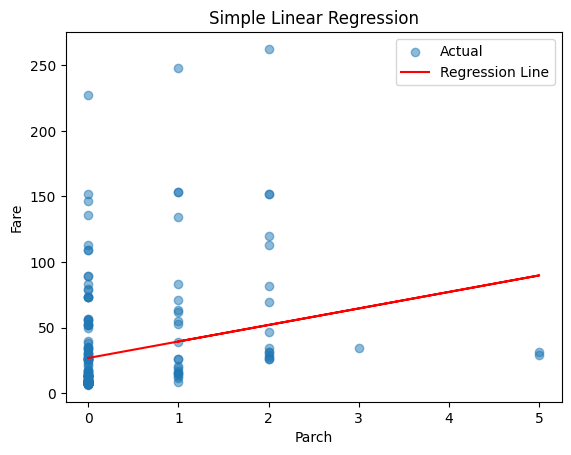

In [7]:
plt.scatter(X_te, y_te, alpha = 0.5, label='Actual')
plt.plot(X_te, pred_simple, color='red', label='Regression Line')
plt.xlabel('Parch')
plt.ylabel('Fare')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

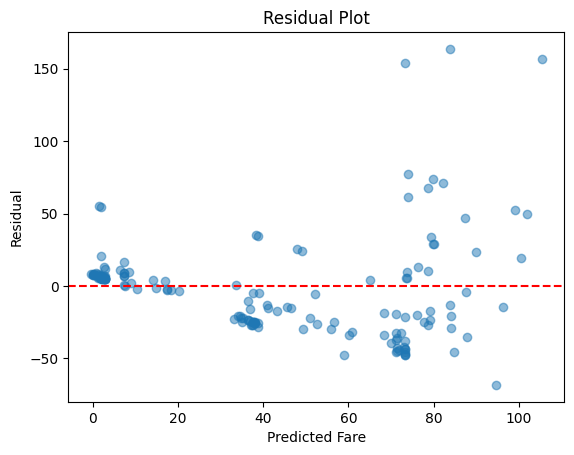

In [8]:
residuals = y_te - pred_multi
plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Fare')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.show()

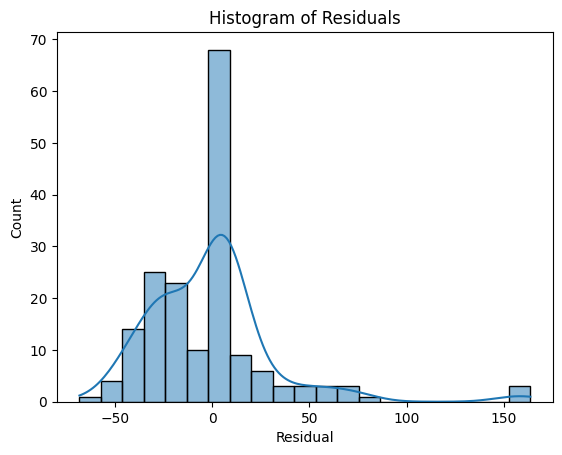

In [9]:
sns.histplot(residuals, kde=True)
plt.xlabel('Residual')
plt.title('Histogram of Residuals')
plt.show()

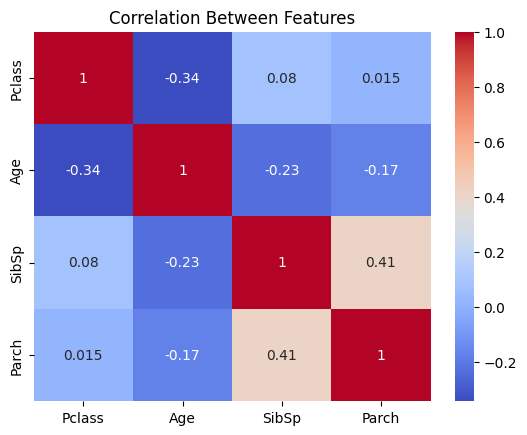

In [10]:
sns.heatmap(X_multi.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Features')
plt.show()